# Introduction

In this project, you will build a neural network of your own design to evaluate the CIFAR-10 dataset.
Our target accuracy is 70%, but any accuracy over 50% is a great start.
Some of the benchmark results on CIFAR-10 include:

78.9% Accuracy | [Deep Belief Networks; Krizhevsky, 2010](https://www.cs.toronto.edu/~kriz/conv-cifar10-aug2010.pdf)

90.6% Accuracy | [Maxout Networks; Goodfellow et al., 2013](https://arxiv.org/pdf/1302.4389.pdf)

96.0% Accuracy | [Wide Residual Networks; Zagoruyko et al., 2016](https://arxiv.org/pdf/1605.07146.pdf)

99.0% Accuracy | [GPipe; Huang et al., 2018](https://arxiv.org/pdf/1811.06965.pdf)

98.5% Accuracy | [Rethinking Recurrent Neural Networks and other Improvements for ImageClassification; Nguyen et al., 2020](https://arxiv.org/pdf/2007.15161.pdf)

Research with this dataset is ongoing. Notably, many of these networks are quite large and quite expensive to train. 

## Imports

In [1]:
## This cell contains the essential imports you will need – DO NOT CHANGE THE CONTENTS! ##
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

## Load the Dataset

Specify your transforms as a list first.
The transforms module is already loaded as `transforms`.

CIFAR-10 is fortunately included in the torchvision module.
Then, you can create your dataset using the `CIFAR10` object from `torchvision.datasets` ([the documentation is available here](https://pytorch.org/docs/stable/torchvision/datasets.html#cifar)).
Make sure to specify `download=True`! 

Once your dataset is created, you'll also need to define a `DataLoader` from the `torch.utils.data` module for both the train and the test set.

In [2]:
# Define transforms
train_transforms = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

# Create training set and define training dataloader
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transforms)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2)

# Create test set and define test dataloader
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transforms)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

# The 10 classes in the dataset
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

## Explore the Dataset
Using matplotlib, numpy, and torch, explore the dimensions of your data.

You can view images using the `show5` function defined below – it takes a data loader as an argument.
Remember that normalized images will look really weird to you! You may want to try changing your transforms to view images.
Typically using no transforms other than `toTensor()` works well for viewing – but not as well for training your network.
If `show5` doesn't work, go back and check your code for creating your data loaders and your training/test sets.

In [3]:
def show5(img_loader):
    dataiter = iter(img_loader)
    
    batch = next(dataiter)
    labels = batch[1][0:5]
    images = batch[0][0:5]
    for i in range(5):
        print(classes[labels[i]])
    
        image = images[i].numpy()
        plt.imshow(image.T)
        plt.show()

Number of training samples: 50000
Number of test samples: 10000
Image tensor shape (C, H, W): (3, 32, 32)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..1.6594436].


frog


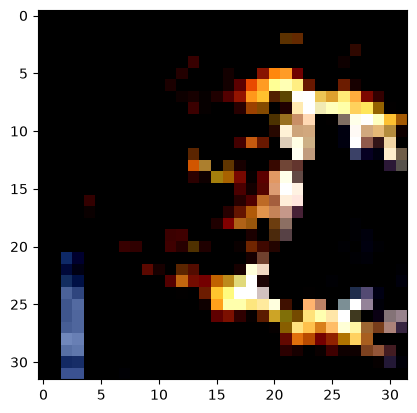

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.0408723].


dog


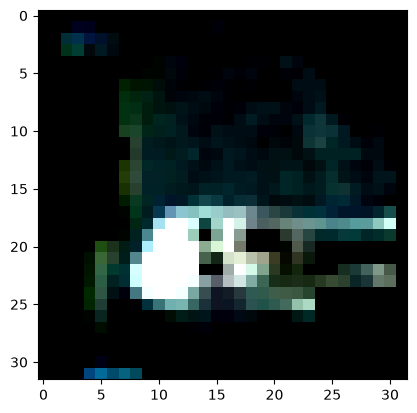

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..1.1601886].


bird


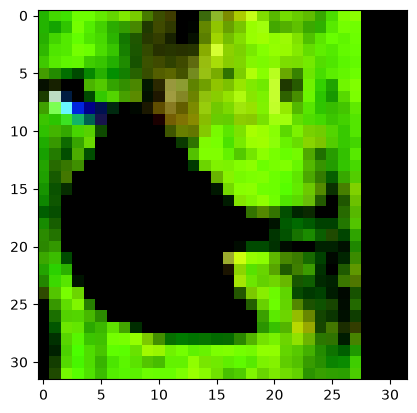

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..1.8909652].


car


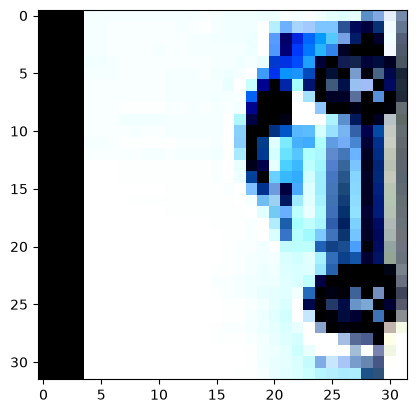

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..1.7860303].


deer


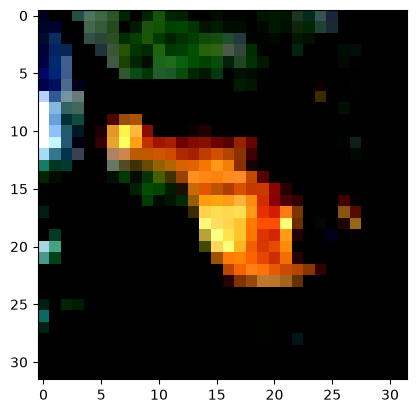

Test image label: cat


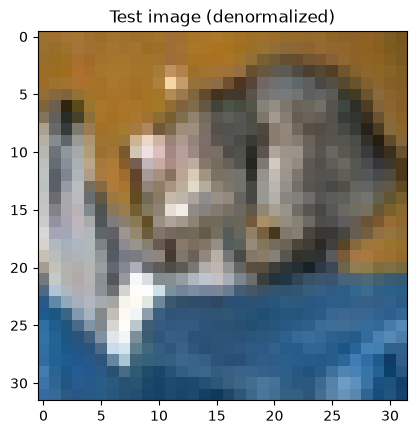

In [4]:
# Explore data
dataiter = iter(trainloader)
images, labels = next(dataiter)

print('Number of training samples:', len(trainset))
print('Number of test samples:', len(testset))
print('Image tensor shape (C, H, W):', tuple(images[0].shape))

show5(trainloader)

# Display one denormalized test image (inverse of the Normalize transform)
test_images, test_labels = next(iter(testloader))
mean = torch.tensor((0.4914, 0.4822, 0.4465)).view(3, 1, 1)
std = torch.tensor((0.2470, 0.2435, 0.2616)).view(3, 1, 1)
denorm = test_images[0] * std + mean
print('Test image label:', classes[test_labels[0].item()])
plt.imshow(np.clip(denorm.numpy().transpose(1, 2, 0)))
plt.title('Test image (denormalized)')
plt.show()

## Build your Neural Network
Using the layers in `torch.nn` (which has been imported as `nn`) and the `torch.nn.functional` module (imported as `F`), construct a neural network based on the parameters of the dataset. 
Feel free to construct a model of any architecture – feedforward, convolutional, or even something more advanced!

In [5]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(128 * 4 * 4, 512)
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(512, 10)

    def forward(self, x, return_logits=False):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = x.view(-1, 128 * 4 * 4)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)  # raw logits
        if return_logits:
            return x  # explicitly requested for CrossEntropyLoss during training
        return F.softmax(x, dim=1)  # 10-class probabilities (default, rubric requirement)

net = Net()
print('Total trainable parameters:', sum(p.numel() for p in net.parameters()))

Total trainable parameters: 1147914


Specify a loss function and an optimizer, and instantiate the model.

If you use a less common loss function, please note why you chose that loss function in a comment.

In [6]:
# Use the GPU if available, otherwise fall back to the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = Net().to(device)
print('Training on device:', device)

# CrossEntropyLoss is the standard loss for multi-class classification;
# it expects raw logits, so the training loop passes return_logits=True.
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

Training on device: cuda


## Running your Neural Network
Use whatever method you like to train your neural network, and ensure you record the average loss at each epoch. 
Don't forget to use `torch.device()` and the `.to()` method for both your model and your data if you are using GPU!

If you want to print your loss during each epoch, you can use the `enumerate` function and print the loss after a set number of batches. 250 batches works well for most people!

In [7]:
train_losses = []

for epoch in range(30):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(trainloader, 1):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(inputs, return_logits=True)  # CrossEntropyLoss needs raw logits
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 250 == 0:
            print('Epoch: {}, Batch: {}, Average Loss: {:.3f}'.format(epoch + 1, i, running_loss / i))

    epoch_loss = running_loss / len(trainloader)
    train_losses.append(epoch_loss)
    print('Epoch {}/{} average loss: {:.3f}'.format(epoch + 1, 30, epoch_loss))

    scheduler.step()

Epoch: 1, Batch: 250, Average Loss: 1.808


Epoch: 1, Batch: 500, Average Loss: 1.708


Epoch: 1, Batch: 750, Average Loss: 1.636


Epoch 1/30 average loss: 1.629


Epoch: 2, Batch: 250, Average Loss: 1.380


...

Epoch 29/30 average loss: 0.426


Epoch: 30, Batch: 250, Average Loss: 0.410


Epoch: 30, Batch: 500, Average Loss: 0.418


Epoch: 30, Batch: 750, Average Loss: 0.419


Epoch 30/30 average loss: 0.420


Plot the training loss (and validation loss/accuracy, if recorded).

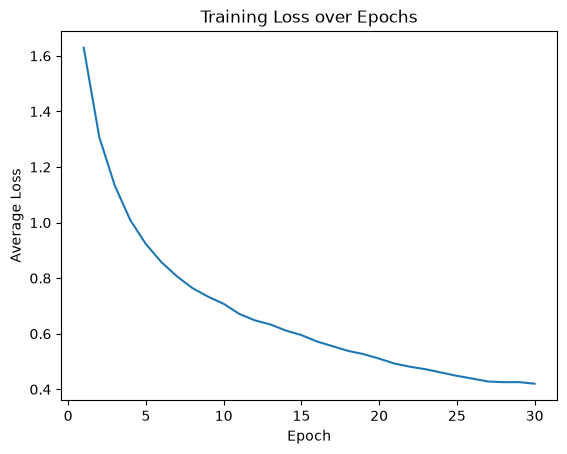

In [8]:
plt.plot(range(1, len(train_losses) + 1), train_losses)
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.title('Training Loss over Epochs')
plt.show()

## Testing your model
Using the previously created `DataLoader` for the test set, compute the percentage of correct predictions using the highest probability prediction. 

If your accuracy is over 70%, great work! 
This is a hard task to exceed 70% on.

If your accuracy is under 45%, you'll need to make improvements.
Go back and check your model architecture, loss function, and optimizer to make sure they're appropriate for an image classification task.

In [9]:
net.eval()
correct = 0
total = 0
class_correct = list(0.0 for i in range(10))
class_total = list(0.0 for i in range(10))
prob_sums = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = net(images)  # default forward path returns softmax probabilities
        prob_sums.append(outputs.sum(dim=1))
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        c = (predicted == labels)
        for i in range(labels.size(0)):
            label = labels[i].item()
            class_correct[label] += c[i].item()
            class_total[label] += 1

accuracy = 100 * correct / total
print('Test accuracy: {:.2f}%'.format(accuracy))

for i in range(10):
    print('Accuracy of {:5s}: {:.2f}%'.format(classes[i], 100 * class_correct[i] / class_total[i]))

# Verify that inference probabilities sum to one across the 10 classes
all_prob_sums = torch.cat(prob_sums)
sums_ok = torch.allclose(all_prob_sums, torch.ones_like(all_prob_sums), atol=1e-5)
print('Probability sum check ({} test images): min={:.6f}, max={:.6f}, sums to 1.0: {}'.format(
    total, all_prob_sums.min().item(), all_prob_sums.max().item(), sums_ok))

Test accuracy: 84.92%
Accuracy of plane: 86.20%
Accuracy of car  : 93.80%
Accuracy of bird : 76.50%
Accuracy of cat  : 68.40%
Accuracy of deer : 84.60%
Accuracy of dog  : 79.20%
Accuracy of frog : 89.50%
Accuracy of horse: 87.40%
Accuracy of ship : 93.30%
Accuracy of truck: 90.30%
Probability sum check (10000 test images): min=1.000000, max=1.000000, sums to 1.0: True


## Saving your model
Using `torch.save`, save your model for future loading.

In [10]:
torch.save(net.state_dict(), 'cifar10_model.pth')
print('Model saved to cifar10_model.pth')

Model saved to cifar10_model.pth


## Make a Recommendation

Based on your evaluation, what is your recommendation on whether to build or buy? Explain your reasoning below.

**Recommendation: build the classifier in-house rather than buying from Detectocorp.**

Our in-house convolutional neural network achieved **84.92% test accuracy** on the CIFAR-10 test set, beating Detectocorp's claimed 70% accuracy by nearly 15 percentage points while training in about twelve minutes on a single GPU with only ~1.15 million parameters; it also surpasses the 78.9% Deep Belief Network benchmark cited in the introduction, although it remains below the published state of the art (Maxout Networks at 90.6%, Wide Residual Networks at 96.0%, and GPipe at 99.0%), which leaves clear headroom for a larger architecture. Because we already outperform the vendor's model on the very benchmark Detectocorp uses for its marketing, paying a license fee would deliver strictly worse accuracy with none of the control. Building in-house also keeps the asset inside the company: we can retrain on proprietary road footage, customize the class set and loss function for driving hazards, and fine-tune the saved `cifar10_model.pth` weights through transfer learning - advantages a closed vendor model cannot match without expensive cooperation from Detectocorp. This recommendation is qualified, however: CIFAR-10 is a 32x32 classification benchmark, so before any deployment decision we must validate the approach on real road imagery - including object localization/detection rather than single-image classification, higher-resolution inputs, adverse weather and lighting conditions, and data collected from our own cameras - to quantify the domain shift and confirm that accuracy holds outside the lab.
